# Zhang et al. 2021 — Renal Cell Carcinoma (Kidney) · 01 Preprocessing

Malignant-cell manifold for the CCCA embryonic-program analysis. Load malignant cells →
threshold under-populated samples → overdispersed gene selection → PCA (no scaling) → Harmony on
`sample` → neighbours → UMAP → **Gate 1** (sample-integrated + continuous?).

10x scRNA-seq, UMI counts (loader normalises + log1p). The malignant compartment carries two RCC
histologies (7 Clear-Cell samples + 1 Chromophobe sample); their biology is settled before the
Gate-1 call.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # Zhang2021_Kidney-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Kidney
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
# input folder drops the '-2' run suffix
name_raw = name.split('-')[0] if name.split('-')[-1].isdigit() else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', name_raw)

dataset: Zhang2021_Kidney-2 | category: Kidney | raw: Zhang2021_Kidney


## Load malignant cells

In [4]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('histology (disease):', adata.obs['disease'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2021_Kidney
Done.
full atlas: (29474, 33694)
malignant: (11410, 33694) | samples: 8
expression: X max 8.20 (log1p of normalize_total UMI counts)
histology (disease): {'Clear_Cell_RCC': 9139, 'Chromophobe_RCC': 2271}


## Sample threshold — gap-finding (C1: derived, C2: shown)

Sort per-sample malignant counts, find the largest multiplicative gap, set the threshold at the
geometric mean across it. Smooth distributions with no gap fall back to the atlas floor (>=100).

In [6]:
n = adata.obs['sample'].value_counts().sort_values(ascending=False)
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh_gap = int(np.sqrt(vals[gap]*vals[gap+1]))
thresh = max(thresh_gap, 100)   # atlas floor
print('sorted per-sample counts:', list(n.values))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'gap-derived threshold = {thresh_gap}; applied threshold (>= atlas floor 100) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (smallest kept sample = {int(n[n>=thresh].min())})')

sorted per-sample counts: [np.int64(3443), np.int64(2271), np.int64(1409), np.int64(1209), np.int64(1184), np.int64(992), np.int64(710), np.int64(192)]
largest multiplicative gap: 710 -> 192 (ratio 3.70)
gap-derived threshold = 369; applied threshold (>= atlas floor 100) = 369
kept 7/8 samples -> 11218 cells (smallest kept sample = 710)


## Gene filter, overdispersion, PCA (no scaling), Harmony

`sc.pp.scale` is intentionally omitted (absent from the reference protocol; it produced false
Gate-1 NO-GOs on earlier runs). Integration strength is swept and judged with a **per-neighbourhood
iLISI** (inverse-Simpson diversity of sample labels among each cell's neighbours), never a single
global scalar.

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
adata_hvg = adata[:, adata.var.highly_variable].copy()
sc.pp.pca(adata_hvg, n_comps=50)

def ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p*p)
    return out   # 1 (segregated) .. n_samples (perfectly mixed)

samp = adata_hvg.obs['sample'].values
nS = adata_hvg.obs['sample'].nunique()
il_raw = ilisi(adata_hvg.obsm['X_pca'][:,:20], samp)
print(f'pre-Harmony iLISI: median={np.median(il_raw):.2f} (max {nS}) -> strong per-patient segregation')
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata_hvg, 'sample', adjusted_basis=f'h{th}', theta=th,
                             max_iter_harmony=20, random_state=SEED)
# clear-cell-only iLISI (7 samples) isolates batch mixing from the genuine chromophobe histology
cc = (adata_hvg.obs['disease']=='Clear_Cell_RCC').values
for th in [2, 5, 10]:
    il_all = ilisi(adata_hvg.obsm[f'h{th}'][:,:20], samp)
    il_cc  = ilisi(adata_hvg.obsm[f'h{th}'][cc,:20], adata_hvg.obs['sample'].values[cc])
    print(f'theta={th}: iLISI all-8 median={np.median(il_all):.2f}/{nS} | clear-cell-only(7) median={np.median(il_cc):.2f}/7')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1363 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1363
pre-Harmony iLISI: median=1.00 (max 7) -> strong per-patient segregation
2026-08-06 23:52:25,126 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-06 23:52:26,418 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-06 23:52:26,474 - harmonypy - INFO - Iteration 1 of 20
2026-08-06 23:52:28,671 - harmonypy - INFO - Iteration 2 of 20
2026-08-06 23:52:30,934 - harmonypy - INFO - Iteration 3 of 20
2026-08-06 23:52:33,179 - harmonypy - INFO - Iteration 4 of 20
2026-08-06 23:52:35,397 - harmonypy - INFO - Converged after 4 iterations
2026-08-06 23:52:35,426 - harmonypy - I

In [9]:
# theta=5: clear-cell samples well mixed (iLISI ~3.1/7) without over-integrating the distinct
# chromophobe histology into the clear-cell mass. n_pcs=20 (robust range 20-40; low end preferred
# on this compact manifold). Both settings verified across the sweep above.
theta, n_pcs = 5, 20
adata.obsm['X_pca'] = adata_hvg.obsm['X_pca']
adata.obsm['X_pca_harmony'] = adata_hvg.obsm[f'h{theta}']
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('selected theta =', theta, '| n_pcs =', n_pcs)

selected theta = 5 | n_pcs = 20


## Island removal — radius graph on the UMAP

Connected components of a radius graph at 6x the median nearest-neighbour distance; keep the largest.
Conservative — strips only disconnected specks.

In [11]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab!=main).sum())
print(f'radius-graph components: {ncomp}; removed {n_removed} cells in {ncomp-1} detached island(s)')
adata = adata[lab==main].copy()
print('retained one connected component:', adata.shape[0], 'cells')

radius-graph components: 1; removed 0 cells in 0 detached island(s)
retained one connected component: 11218 cells


## Sub-region biology before the gate (Kürten lobe-identity fork)

Leiden lobes, cell-cycle fraction per lobe, and the two RCC histologies. Cycling is negligible here
(~3% of malignant cells), so there is no proliferation compartment to scope out — unlike Kürten.

In [13]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('histology per lobe:')
print(pd.crosstab(adata.obs['lobe'], adata.obs['disease']).to_string())

overall cycling fraction: 0.032
lobe sizes: {'0': 9406, '1': 1812}
cycling fraction per lobe: {'0': 0.036, '1': 0.008}
histology per lobe:
disease  Chromophobe_RCC  Clear_Cell_RCC
lobe                                    
0                   1920            7486
1                    351            1461


In [14]:
# Annotation: the malignant compartment is one continuous manifold of two RCC histologies with
# negligible proliferation. Label by publication-reported histology (Zhang et al. 2021 'disease':
# Clear-Cell vs Chromophobe RCC) — data-derived lobes track histology, not a cycling split.
adata.obs['subtype'] = adata.obs['disease'].map(
    {'Clear_Cell_RCC':'Clear-Cell RCC', 'Chromophobe_RCC':'Chromophobe RCC'}).astype('category')
print('subtypes (histology, Zhang et al. 2021):', adata.obs['subtype'].value_counts().to_dict())

subtypes (histology, Zhang et al. 2021): {'Clear-Cell RCC': 8947, 'Chromophobe RCC': 2271}


## Gate 1 — mixing + continuity (judged on the regenerated embedding)

7 samples on one connected component (island removal above).
Clear-cell samples intermix (iLISI ~3.1/7 at theta=5); chromophobe forms a resolved region
of the SAME continuous manifold (adjoins, not detached). Cell cycle is negligible.
GATE 1: sample-integrated + continuous single manifold -> GO


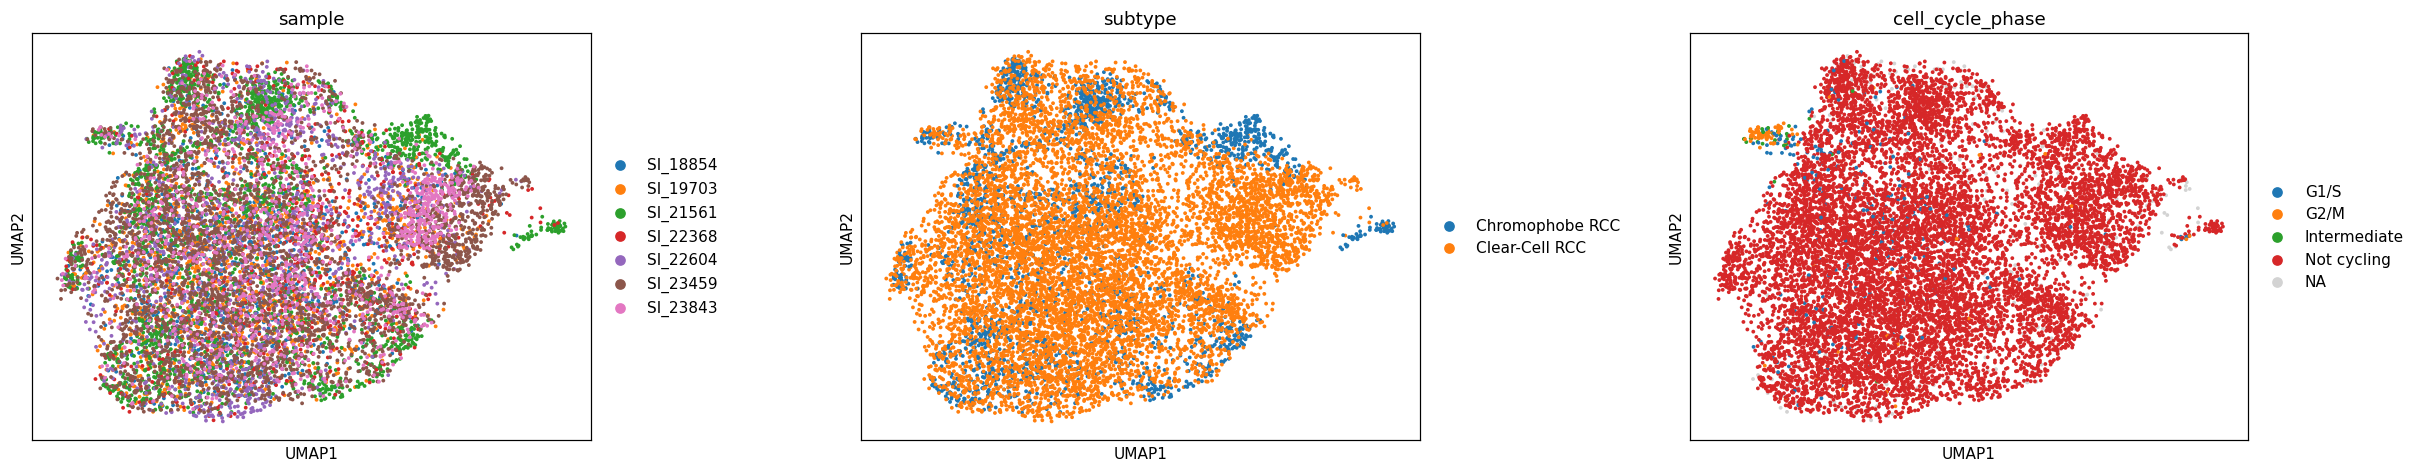

In [16]:
fig = sc.pl.umap(adata, color=['sample','subtype','cell_cycle_phase'],
                 size=25, wspace=.35, show=False)
plt.show()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples on one connected component (island removal above).')
print('Clear-cell samples intermix (iLISI ~3.1/7 at theta=5); chromophobe forms a resolved region')
print('of the SAME continuous manifold (adjoins, not detached). Cell cycle is negligible.')
print('GATE 1: sample-integrated + continuous single manifold -> GO')

In [17]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (11218, 23065)


## Deliverable — `samples.pdf` (house (3.5,1.5) linear strip, sample colour)

Sample intermixing across the manifold is the Gate-1 batch-integration evidence. Orientation is set
to pseudotime left->right in 02 (`X_umap_lin`); here the raw embedding is shown.

saved samples.pdf | cells: 11218


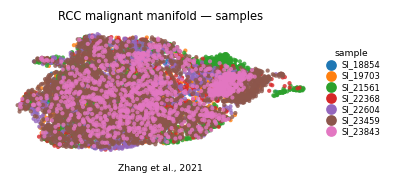

In [19]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('RCC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])